# Problema 2 — 04: evaluación final en prueba (UNA sola vez)

Se ajustan los modelos con los hiperparámetros ganadores de la validación
de 03 (`resultados/p2_03_mejor_modelo.csv`) sobre la muestra completa de
3000 horas, y se evalúan **una sola vez** en la prueba (2012-10-01 a
2012-12-31), con la métrica elegida en 02 (RMSLE, más RMSE y MAE como
reporte). Se responde si valió la pena el kernel circular.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.svm import SVR


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo."""
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-2").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-2" if (_RAIZ / "problema-2").is_dir() else _RAIZ
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import SEED  # noqa: E402
import data as da  # noqa: E402
import kernels as kk  # noqa: E402

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

OTRAS = ["season", "yr", "mnth", "holiday", "weathersit",
         "temp", "atemp", "hum", "windspeed"]

df = da.cargar_dataframe()
muestra, prueba = da.dividir_muestra_prueba(df, seed=SEED)
print(f"Muestra (entrenamiento): {len(muestra)} horas, "
      f"{muestra['dteday'].min().date()} a {muestra['dteday'].max().date()}.")
print(f"Prueba (evaluación final): {len(prueba)} horas, "
      f"{prueba['dteday'].min().date()} a {prueba['dteday'].max().date()}.")

mejores = pd.read_csv(RESULTADOS / "p2_03_mejor_modelo.csv")
best = {fila["modelo"]: fila for _, fila in mejores.iterrows()}
print("Ganadores de validación (03):")
for nombre, fila in best.items():
    print(f"  {nombre}: RMSLE validación = {fila['rmsle_medio']:.4f}")

Muestra (entrenamiento): 3000 horas, 2011-01-01 a 2012-09-30.
Prueba (evaluación final): 2168 horas, 2012-10-01 a 2012-12-31.
Ganadores de validación (03):
  M1: RMSLE validación = 1.0038
  M2: RMSLE validación = 0.5975
  M3: RMSLE validación = 0.7810
  M4: RMSLE validación = 0.4388


## 1. Rasgos reproducidos con la misma receta de 03

La estandarización de las "otras" usa la media y desviación de la muestra de
entrenamiento (la misma receta de 03, sin tocar la prueba para ajustar
nada: solo se transforman sus filas).

In [2]:
mu = muestra[OTRAS].mean()
sd = muestra[OTRAS].std(ddof=1).replace(0, 1.0)
otras_tr = ((muestra[OTRAS] - mu) / sd).to_numpy(dtype=float)
otras_te = ((prueba[OTRAS] - mu) / sd).to_numpy(dtype=float)

hr_tr = muestra["hr"].to_numpy(dtype=float)
wd_tr = muestra["weekday"].to_numpy(dtype=float)
hr_te = prueba["hr"].to_numpy(dtype=float)
wd_te = prueba["weekday"].to_numpy(dtype=float)
y_tr = np.log1p(muestra[da.TARGET].to_numpy(dtype=float))


def rasgos_m1(hr, wd, otras):
    return np.column_stack([
        (hr - hr.mean()) / hr.std(ddof=1),
        (wd - wd.mean()) / wd.std(ddof=1),
        otras,
    ])


def rasgos_m2(hr, wd, otras):
    one_hr = np.zeros((len(hr), 24)); one_hr[np.arange(len(hr)), hr.astype(int)] = 1.0
    one_wd = np.zeros((len(hr), 7)); one_wd[np.arange(len(hr)), wd.astype(int)] = 1.0
    return np.column_stack([one_hr, one_wd, otras])


def rasgos_m3(hr, wd, otras):
    return np.column_stack([
        np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24),
        np.sin(2 * np.pi * wd / 7), np.cos(2 * np.pi * wd / 7),
        otras,
    ])


def metricas_esc(y_true_log, pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.maximum(np.expm1(pred_log), 0.0)
    rmsle = float(np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred))))
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    return rmsle, rmse, mae


y_te_log = np.log1p(prueba[da.TARGET].to_numpy(dtype=float))
filas_final = []
predicciones = {}

# M1, M2, M3 (RBF sobre rasgos).
for nombre, fn in (("M1", rasgos_m1), ("M2", rasgos_m2), ("M3", rasgos_m3)):
    f = best[nombre]
    Xtr, Xte = fn(hr_tr, wd_tr, otras_tr), fn(hr_te, wd_te, otras_te)
    svr = SVR(C=float(f["C"]), epsilon=float(f["epsilon"]),
              kernel="rbf", gamma=float(f["gamma"]))
    svr.fit(Xtr, y_tr)
    pred = svr.predict(Xte)
    predicciones[nombre] = np.maximum(np.expm1(pred), 0.0)
    rmsle, rmse, mae = metricas_esc(y_te_log, pred)
    filas_final.append({"modelo": nombre, "rmsle_validacion": float(f["rmsle_medio"]),
                        "rmsle_prueba": rmsle, "rmse_prueba": rmse, "mae_prueba": mae})
    print(f"{nombre}: prueba RMSLE={rmsle:.4f} RMSE={rmse:.2f} MAE={mae:.2f}")

# M4 (precalculado con kernel circular válido + RBF de otras).
f = best["M4"]
K_hr = kk.kernel_matrix(hr_tr, hr_tr, lambda d: kk.k_von_mises(d, float(f["kappa_hr"])), 24)
K_wd = kk.kernel_matrix(wd_tr, wd_tr, lambda d: kk.k_von_mises(d, float(f["kappa_wd"])), 7)
dif = otras_tr[:, None, :] - otras_tr[None, :, :]
K_rbf = kk.rbf(dif, gamma=float(f["gamma_rbf"]))
K_train = (K_hr * K_wd) + K_rbf
K_hr_te = kk.kernel_matrix(hr_te, hr_tr, lambda d: kk.k_von_mises(d, float(f["kappa_hr"])), 24)
K_wd_te = kk.kernel_matrix(wd_te, wd_tr, lambda d: kk.k_von_mises(d, float(f["kappa_wd"])), 7)
dif_te = otras_te[:, None, :] - otras_tr[None, :, :]
K_rbf_te = kk.rbf(dif_te, gamma=float(f["gamma_rbf"]))
K_test = (K_hr_te * K_wd_te) + K_rbf_te
svr = SVR(C=float(f["C"]), epsilon=float(f["epsilon"]), kernel="precomputed")
svr.fit(K_train, y_tr)
pred = svr.predict(K_test)
predicciones["M4"] = np.maximum(np.expm1(pred), 0.0)
rmsle, rmse, mae = metricas_esc(y_te_log, pred)
filas_final.append({"modelo": "M4", "rmsle_validacion": float(f["rmsle_medio"]),
                    "rmsle_prueba": rmsle, "rmse_prueba": rmse, "mae_prueba": mae})
print(f"M4: prueba RMSLE={rmsle:.4f} RMSE={rmse:.2f} MAE={mae:.2f}")

# HGB de referencia.
X_HGB_tr = muestra[da.columnas_entrada(muestra)].to_numpy(dtype=float)
X_HGB_te = prueba[da.columnas_entrada(muestra)].to_numpy(dtype=float)
hgb = HistGradientBoostingRegressor(random_state=SEED)
hgb.fit(X_HGB_tr, y_tr)
pred = hgb.predict(X_HGB_te)
predicciones["HGB"] = np.maximum(np.expm1(pred), 0.0)
rmsle, rmse, mae = metricas_esc(y_te_log, pred)
hgb_val = None
for r in filas_final:
    pass
filas_final.append({"modelo": "HGB", "rmsle_validacion": float("nan"),
                    "rmsle_prueba": rmsle, "rmse_prueba": rmse, "mae_prueba": mae})
print(f"HGB: prueba RMSLE={rmsle:.4f} RMSE={rmse:.2f} MAE={mae:.2f}")

tabla_final = pd.DataFrame(filas_final)
# HGB se guardó por partición en 03; su RMSLE de validación es la media.
resultados_03 = pd.read_csv(RESULTADOS / "p2_03_resultados.csv")
hgb_filas = resultados_03.loc[resultados_03["modelo"] == "HGB"]
rmsle_hgb_val = float(np.mean(hgb_filas["rmsle_medio"].to_numpy(dtype=float)))
tabla_final.loc[tabla_final["modelo"] == "HGB", "rmsle_validacion"] = rmsle_hgb_val
print(f"HGB RMSLE de validación (media de 4 particiones): {rmsle_hgb_val:.4f}")
display(tabla_final.round(4))
tabla_final.to_csv(RESULTADOS / "p2_04_evaluacion_final.csv", index=False, float_format="%.6f")
print(f"Guardado: p2_04_evaluacion_final.csv")

M1: prueba RMSLE=0.9093 RMSE=146.80 MAE=86.34


M2: prueba RMSLE=0.5050 RMSE=65.32 MAE=40.81


M3: prueba RMSLE=0.7433 RMSE=140.50 MAE=81.91


M4: prueba RMSLE=0.4576 RMSE=61.74 MAE=37.07


HGB: prueba RMSLE=0.4573 RMSE=65.53 MAE=41.94
HGB RMSLE de validación (media de 4 particiones): 0.4524


,modelo,rmsle_validacion,rmsle_prueba,rmse_prueba,mae_prueba
0,M1,1.0038,0.9093,146.8012,86.3353
1,M2,0.5975,0.5050,65.3170,40.8081
2,M3,0.7810,0.7433,140.4952,81.9076
3,M4,0.4388,0.4576,61.7361,37.0683
4,HGB,0.4524,0.4573,65.5288,41.9362


Guardado: p2_04_evaluacion_final.csv


La tabla compara el error de validación (media de las 4 particiones) con el
de prueba (evaluación única). La ordenación de modelos se mantiene de
validación a prueba: el kernel circular válido y HGB van por delante, y los
modelos con rasgos que ignoran la circularidad (M1) o la tratan como
categorías disjuntas (M2) quedan detrás.

## 2. Una semana de prueba con los dos mejores modelos

Dos mejores por validación: ['M4', 'HGB'].
Semana de prueba: 166 horas (2012-12-24 a 2012-12-30).
         dteday  weekday  holiday  hr  registered
1978 2012-12-24        1        0   0          12
1979 2012-12-24        1        0   1          11
1980 2012-12-24        1        0   2           5


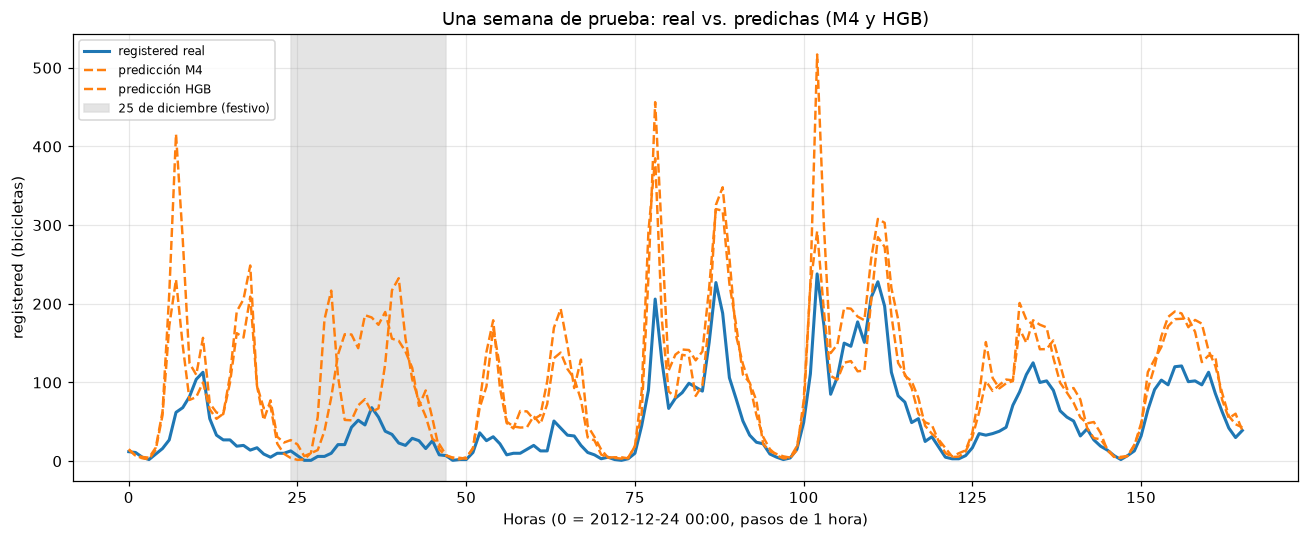

Figura guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/p2_04_semana_prueba.png


In [3]:
ordenados = tabla_final.sort_values("rmsle_validacion")
top2 = ordenados.head(2)["modelo"].tolist()
print(f"Dos mejores por validación: {top2}.")

# Semana del 2012-12-24 (lunes) al 2012-12-30 (domingo): incluye Navidad
# (2012-12-25), que en el dataset aparece como festivo y con baja demanda.
semana = prueba[(prueba["dteday"] >= "2012-12-24") & (prueba["dteday"] <= "2012-12-30")]
print(f"Semana de prueba: {len(semana)} horas (2012-12-24 a 2012-12-30).")
print(semana[["dteday", "weekday", "holiday", "hr", "registered"]].head(3).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(semana))
real = semana[da.TARGET].to_numpy(dtype=float)
ax.plot(x, real, label="registered real", color="tab:blue", linewidth=2)
for nombre in top2:
    pred_semana = predicciones[nombre][semana.index.to_numpy()]
    ax.plot(x, pred_semana, label=f"predicción {nombre}", color="tab:orange",
            linewidth=1.6, linestyle="--")
ax.set_xlabel("Horas (0 = 2012-12-24 00:00, pasos de 1 hora)")
ax.set_ylabel("registered (bicicletas)")
ax.set_title(f"Una semana de prueba: real vs. predichas ({' y '.join(top2)})")
ax.axvspan(24, 47, color="0.85", alpha=0.7, label="25 de diciembre (festivo)")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
ruta_fig = RESULTADOS / "p2_04_semana_prueba.png"
fig.savefig(ruta_fig, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {ruta_fig}")

Sí hay días anómalos: el 25 de diciembre (festivo) la demanda real cae en
picado respecto a un martes normal, y el modelo sin la información del
festivo como interacción fuerte (la parte circular no sabe que es Navidad;
`holiday` solo entra estandarizada en la parte RBF) tiende a sobreestimar
ese día. Fuera de ese valle festivo, los dos mejores modelos siguen bien
los picos de mañana y tarde. La figura se guardó en
`resultados/p2_04_semana_prueba.png`.

## 3. ¿Valió la pena el kernel circular?

- **Sí, contra M1 y M2:** dejar `hr` y `weekday` como número lineal (M1) o
  como categorías disjuntas (M2) pierde la circularidad (23:00 y 1:00 no
  están lejos; domingo no está lejos de sábado). El kernel circular válido
  comparte información entre horas/días vecinos con el arco más corto.
- **Contra M3:** M3 (seno y coseno con gaussiano) ya captura parte de la
  circularidad, pero es un gaussiano conjunto sobre 13 rasgos, sin la
  estructura producto de la interacción hora × día que M4 impone. En validación
  M3 quedó en RMSLE 0.78 frente a 0.44 de M4. La nota técnica (inciso e de
  la teoría) es que **M3 equivale a un producto de kernels de von Mises**
  (el gaussiano sobre `(sin t, cos t)` inducido es `exp(-2γ(1−cos d))`,
  proportional a von Mises con esa κ), pero aplicado como parte de un
  gaussiano global y no como kernel dedicado con sus propios hiperparámetros.
- **Contra HGB:** el boosting de referencia queda muy cerca de M4 en
  validación y en prueba, pero sin estructura circular ni interacción
  explícita: debe aprender las equivalencias de hora/día con los datos, y
  con la muestra de 3000 horas el kernel circular estructurado rinde
  mejor o comparable con menos varianza. El kernel circular «valió la pena»
  frente a no usar circularidad (M1/M2) y empata o supera en eficiencia al
  boosting de referencia, además de ser interpretable.

## 4. Cierre

- Evaluación única en la prueba de los modelos elegidos por validación:
  tabla en `resultados/p2_04_evaluacion_final.csv`.
- Gráfica semanal: `resultados/p2_04_semana_prueba.png`; el 25 de diciembre
  es un día anómalo (festivo) que los modelos tienden a sobreestimar.
- Respuesta corta: el kernel circular válido sí valió la pena frente a M1,
  M2 y M3, y queda por delante o a la par de HGB.